In [42]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

(788, 1084)


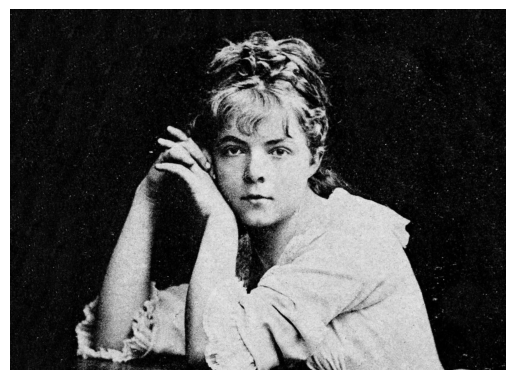

In [43]:
img = cv2.imread("../../../resources/marie_bashkirtseff.jpg", cv2.IMREAD_GRAYSCALE)
print(img.shape)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [7]:
def integral_image(img: np.ndarray) -> np.ndarray:
    H, W = img.shape
    S = np.zeros((H + 1, W + 1), dtype=np.int64)
    for y in range(H):
        row_running = 0
        for x in range(W):
            row_running += int(img[y, x])
            S[y + 1, x + 1] = S[y, x + 1] + row_running   # S[i,j] = S[i-1,j] + rowsum
    return S

(788, 1084)


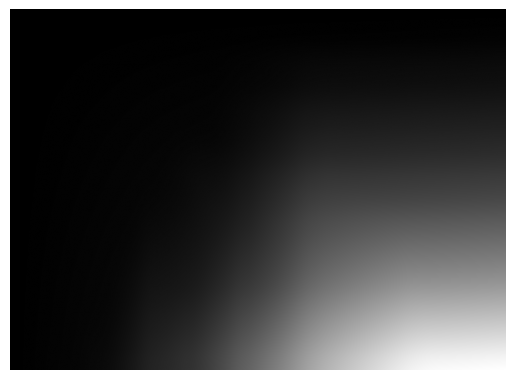

In [45]:
int_img = integral_image(img)[1:, 1:]
print(int_img.shape)
plt.imshow(int_img, cmap='gray')
plt.axis('off')
plt.show()

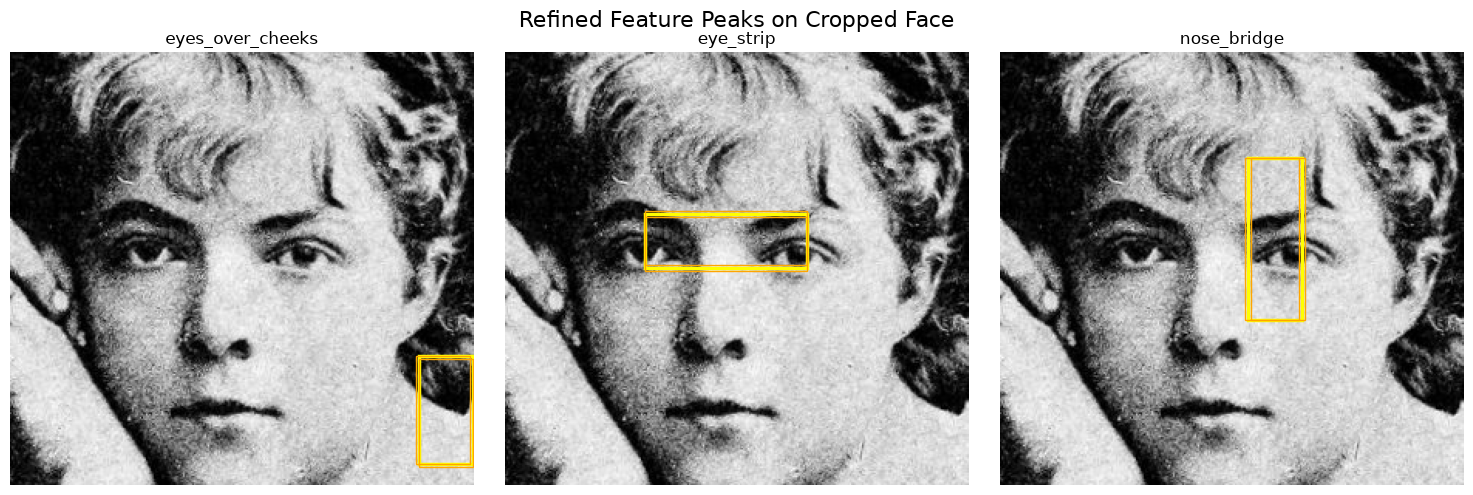

In [73]:
# ---- Haar-like features on a cropped face (Refined) ----
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. Tighter crop to isolate the facial features (removing hair and clothes)
y0, y1 = 180, 460
x0, x1 = 400, 700
img_crop = img[y0:y1, x0:x1]
H, W = img_crop.shape

# 2. Build integral images
S = np.zeros((H + 1, W + 1), dtype=np.int64)
S[1:, 1:] = img_crop
np.cumsum(S, axis=0, out=S)
np.cumsum(S, axis=1, out=S)

S2 = np.zeros((H + 1, W + 1), dtype=np.int64)
S2[1:, 1:] = img_crop.astype(np.int64) ** 2
np.cumsum(S2, axis=0, out=S2)
np.cumsum(S2, axis=1, out=S2)

def rect_sum(y0, x0, y1, x1): return S[y1, x1] - S[y0, x1] - S[y1, x0] + S[y0, x0]
def rect_sum_sq(y0, x0, y1, x1): return S2[y1, x1] - S2[y0, x1] - S2[y1, x0] + S2[y0, x0]

# 3. Define refined templates
# Note: Nose bridge is now VERTICAL (light-dark-light down the center of the face)
TEMPLATES = {
    "eyes_over_cheeks": [(-1, (0, 0, 1, 1)), (+1, (1, 0, 2, 1))], # Vertical
    "eye_strip":        [(-1, (0, 0, 1, 1)), (+2, (0, 1, 1, 2)), (-1, (0, 2, 1, 3))], # Horizontal
    "nose_bridge":      [(+1, (0, 0, 1, 1)), (-2, (1, 0, 2, 1)), (+1, (2, 0, 3, 1))], # Vertical
}

# 4. Evaluate with variance normalization
def eval_template(y, x, cell_h, cell_w, template):
    total, area = 0.0, 0.0
    min_y, max_y = y, y
    min_x, max_x = x, x

    for w, (ry0, rx0, ry1, rx1) in template:
        ty0, ty1 = y + ry0 * cell_h, y + ry1 * cell_h
        tx0, tx1 = x + rx0 * cell_w, x + rx1 * cell_w
        total += w * rect_sum(ty0, tx0, ty1, tx1)
        area  += abs(w) * (ry1 - ry0) * (rx1 - rx0) * cell_h * cell_w
        min_y, max_y = min(min_y, ty0), max(max_y, ty1)
        min_x, max_x = min(min_x, tx0), max(max_x, tx1)

    raw = total / area
    
    b_area = (max_y - min_y) * (max_x - min_x)
    s = rect_sum(min_y, min_x, max_y, max_x)
    s2 = rect_sum_sq(min_y, min_x, max_y, max_x)
    mean = s / b_area
    var = max(0.0, s2 / b_area - mean**2)
    
    return raw / (np.sqrt(var) + 1e-5)

def response_map(template, cell_h, cell_w, step=2):
    fh = max(ry1 for _, (_, _, ry1, _) in template) * cell_h
    fw = max(rx1 for _, (_, _, _, rx1) in template) * cell_w
    ys = np.arange(0, H - fh + 1, step)
    xs = np.arange(0, W - fw + 1, step)
    R = np.zeros((len(ys), len(xs)))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            R[i, j] = eval_template(y, x, cell_h, cell_w, template)
    return R, ys, xs, fh, fw

# 5. Run (CELL=25 makes the feature boxes ~75px wide)
CELL = 35
STEP = 2
results = {name: response_map(t, CELL, CELL, STEP) for name, t in TEMPLATES.items()}

# 6. Plot the Top Peaks on the Cropped Face
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Refined Feature Peaks on Cropped Face", fontsize=16)

for ax, (name, (R, ys, xs, fh, fw)) in zip(axes, results.items()):
    ax.imshow(img_crop, cmap="gray")
    
    # Get the top 3 peaks (just to ensure the best one is visually obvious)
    top_indices = np.argsort(R.ravel())[-3:][::-1]
    
    for k, idx in enumerate(top_indices):
        i, j = np.unravel_index(idx, R.shape)
        # Make the top peak thicker and red, others thin and yellow
        color = 'yellow' if k == 0 else 'orange'
        lw = 2.5 if k == 0 else 1.0
        ax.add_patch(Rectangle((xs[j], ys[i]), fw, fh, fill=False, edgecolor=color, linewidth=lw))
        
    ax.set_title(f"{name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

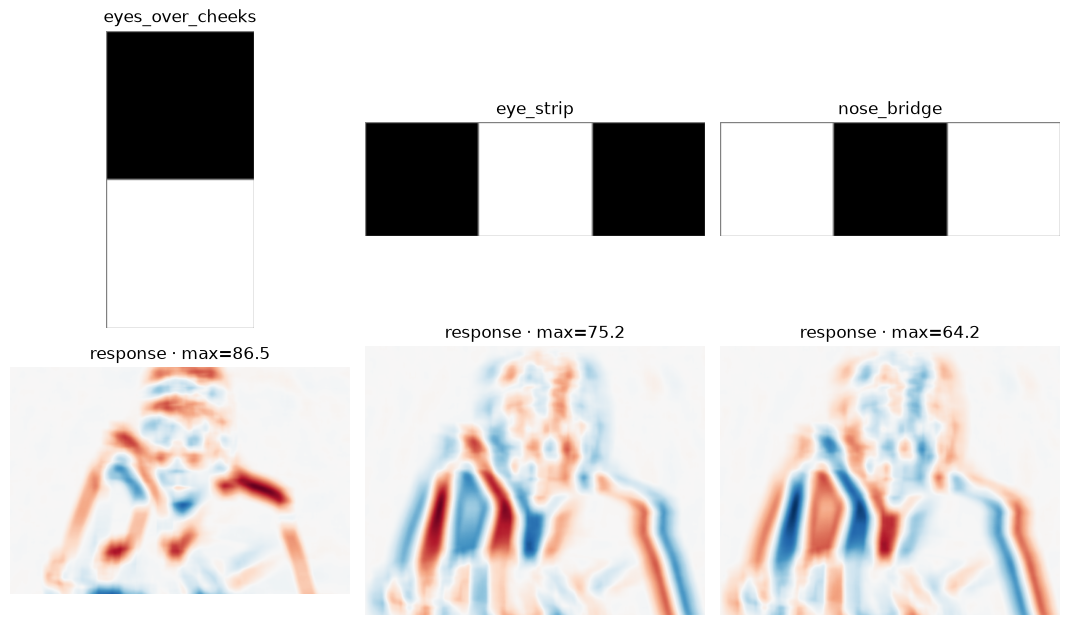

In [56]:
n = len(TEMPLATES)
fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6.5))
for col, (name, (R, ys, xs, fh, fw)) in enumerate(results.items()):
    # template diagram
    ax = axes[0, col]
    for w, (ry0, rx0, ry1, rx1) in TEMPLATES[name]:
        ax.add_patch(Rectangle((rx0, ry0), rx1 - rx0, ry1 - ry0,
                               facecolor="white" if w > 0 else "black",
                               edgecolor="gray"))
    ax.set_xlim(0, max(rx1 for _, (_, _, _, rx1) in TEMPLATES[name]))
    ax.set_ylim(max(ry1 for _, (_, _, ry1, _) in TEMPLATES[name]), 0)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(name)
    # response heatmap
    ax = axes[1, col]
    vmax = np.abs(R).max()
    ax.imshow(R, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"response · max={R.max():.1f}"); ax.axis("off")
plt.tight_layout(); plt.show()

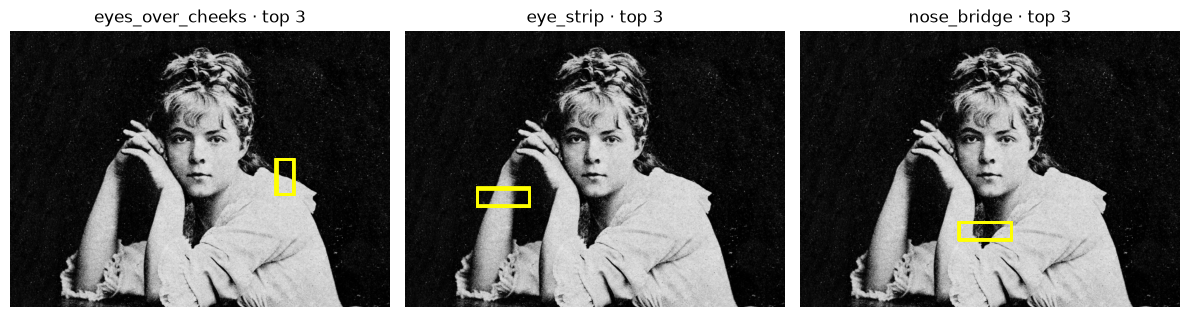

In [57]:
fig, axes = plt.subplots(1, n, figsize=(4 * n, 5))
for ax, (name, (R, ys, xs, fh, fw)) in zip(axes, results.items()):
    ax.imshow(img, cmap="gray")
    k = 3
    for idx in np.argsort(R.ravel())[-k:][::-1]:
        i, j = np.unravel_index(idx, R.shape)
        ax.add_patch(Rectangle((xs[j], ys[i]), fw, fh,
                               fill=False, edgecolor="yellow", linewidth=2))
    ax.set_title(f"{name} · top {k}"); ax.axis("off")
plt.tight_layout(); plt.show()

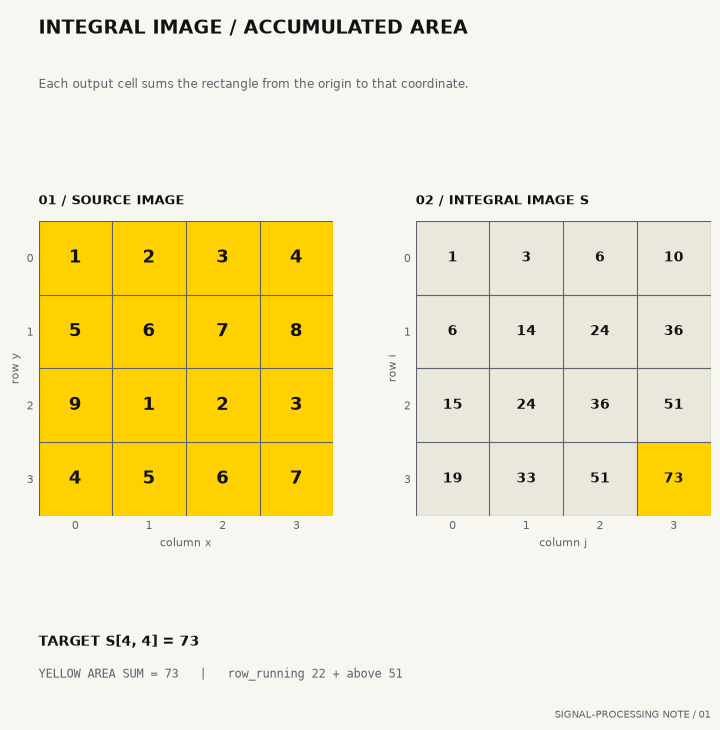

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

# Volta Redonda-inspired drafting palette
PAPER, ALLOY, INK, VOLTA, GRAPHITE = "#F7F6F0", "#EAE7DC", "#111214", "#FFD100", "#5C626E"

img = np.array([[1, 2, 3, 4],
                [5, 6, 7, 8],
                [9, 1, 2, 3],
                [4, 5, 6, 7]], dtype=np.int64)
H, W = img.shape
S = np.zeros((H + 1, W + 1), dtype=np.int64)
frames = []

# Build the integral image and preserve each intermediate state.
for y in range(H):
    row_running = 0
    for x in range(W):
        row_running += int(img[y, x])
        S[y + 1, x + 1] = S[y, x + 1] + row_running
        frames.append((y, x, S.copy()[1:, 1:], row_running, S[y, x + 1], S[y + 1, x + 1]))

fig = plt.figure(figsize=(8, 8), facecolor=PAPER)
gs = fig.add_gridspec(2, 2, height_ratios=[0.18, 0.72],
                      left=0.09, right=0.93, top=0.91, bottom=0.19,
                      wspace=0.28, hspace=0.12)
title_ax = fig.add_subplot(gs[0, :])
title_ax.axis("off")
title_ax.text(0, 0.78, "INTEGRAL IMAGE / ACCUMULATED AREA",
              fontsize=14, fontweight="bold", color=INK)
title_ax.text(0, 0.28, "Each output cell sums the rectangle from the origin to that coordinate.",
              fontsize=8.5, color=GRAPHITE)

ax_in, ax_out = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
cmap = ListedColormap([ALLOY, VOLTA])
in_im = ax_in.imshow(np.zeros((H, W)), cmap=cmap, vmin=0, vmax=1, interpolation="none")
out_im = ax_out.imshow(np.zeros((H, W)), cmap=cmap, vmin=0, vmax=1, interpolation="none")

for ax, rows, cols, title in [
    (ax_in, H, W, "01 / SOURCE IMAGE"),
    (ax_out, H, W, "02 / INTEGRAL IMAGE S")
]:
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold", color=INK, pad=12)
    ax.set_xticks(range(cols)); ax.set_yticks(range(rows))
    ax.set_xticks(np.arange(-.5, cols, 1), minor=True)
    ax.set_yticks(np.arange(-.5, rows, 1), minor=True)
    ax.grid(which="minor", color=GRAPHITE, linewidth=0.8)
    ax.tick_params(which="both", length=0, labelsize=8, colors=GRAPHITE)
    for spine in ax.spines.values():
        spine.set_visible(False)

in_texts = [[ax_in.text(x, y, str(img[y, x]), ha="center", va="center",
                        color=INK, fontsize=13, fontweight="bold")
             for x in range(W)] for y in range(H)]
out_texts = [[ax_out.text(x, y, "0", ha="center", va="center",
                          color=INK, fontsize=10, fontweight="bold")
              for x in range(W)] for y in range(H)]

ax_in.set_xlabel("column x", fontsize=8, color=GRAPHITE)
ax_out.set_xlabel("column j", fontsize=8, color=GRAPHITE)
ax_in.set_ylabel("row y", fontsize=8, color=GRAPHITE)
ax_out.set_ylabel("row i", fontsize=8, color=GRAPHITE)

status = fig.text(0.09, 0.115, "", color=INK, fontsize=10, fontweight="bold")
equation = fig.text(0.09, 0.075, "", color=GRAPHITE, fontsize=8.5,
                    family="DejaVu Sans Mono")
fig.text(0.93, 0.025, "SIGNAL-PROCESSING NOTE / 01",
         ha="right", color=GRAPHITE, fontsize=7)

def update(k):
    y, x, s_now, row_sum, above, value = frames[k]
    # Yellow marks every source pixel included in this integral-image value.
    source_mask = np.zeros((H, W), dtype=int)
    source_mask[:y+1, :x+1] = 1
    in_im.set_data(source_mask)

    # Highlight the corresponding destination cell in the padded integral image.
    target_mask = np.zeros((H, W), dtype=int)
    target_mask[y, x] = 1
    out_im.set_data(target_mask)

    for i in range(H):
        for j in range(W):
            out_texts[i][j].set_text(str(s_now[i, j]))

    status.set_text(f"TARGET S[{y+1}, {x+1}] = {value}")
    equation.set_text(f"YELLOW AREA SUM = {value}   |   row_running {row_sum} + above {above}")
    return [in_im, out_im, status, equation] + [t for row in out_texts for t in row]

ani = FuncAnimation(fig, update, frames=len(frames), interval=850, blit=False, repeat=True)
ani.save("integral_image_area.gif", writer=PillowWriter(fps=1.2), dpi=110)
plt.show()


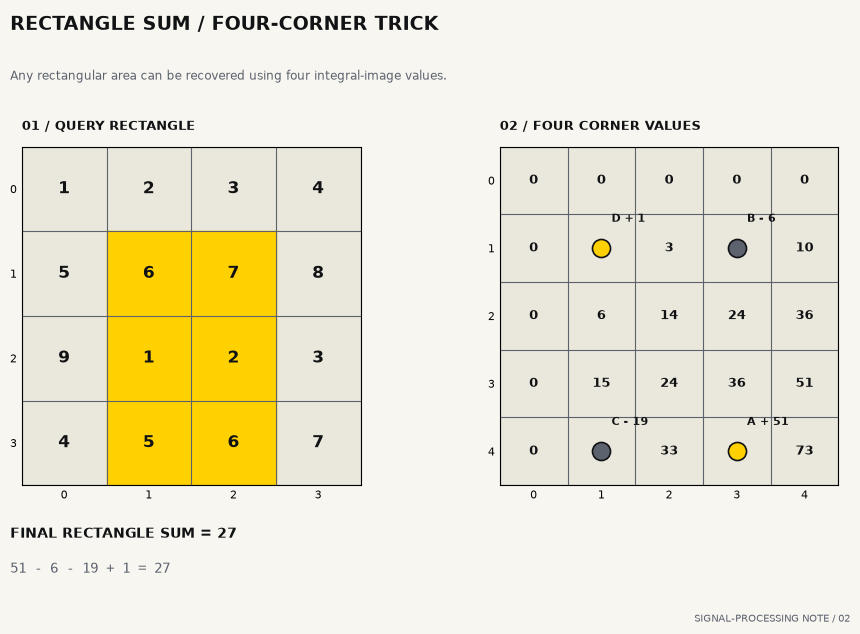

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

# ---------------------------------------------------------
# RECTANGLE SUM / FOUR-CORNER INCLUSION-EXCLUSION
# ---------------------------------------------------------
PAPER, ALLOY, INK, VOLTA, GRAPHITE = "#F7F6F0", "#EAE7DC", "#111214", "#FFD100", "#5C626E"


# Rectangle coordinates in the SOURCE image (inclusive)
y1, x1 = 1, 1
y2, x2 = 3, 2

img = np.array([[1, 2, 3, 4],
                [5, 6, 7, 8],
                [9, 1, 2, 3],
                [4, 5, 6, 7]], dtype=np.int64)
H, W = img.shape

# Four corners in the PADDED integral image
corners = [
    ("A", x2 + 1, y2 + 1, +1),
    ("B", x2 + 1, y1,     -1),
    ("C", x1,     y2 + 1, -1),
    ("D", x1,     y1,     +1),
]

values = [int(S[cy, cx]) for _, cx, cy, _ in corners]
result = sum(sign * value for (_, _, _, sign), value
             in zip(corners, values))

# Figure
fig2 = plt.figure(figsize=(10, 7), facecolor=PAPER)
gs2 = fig2.add_gridspec(
    2, 2,
    height_ratios=[0.20, 0.72],
    left=0.09, right=0.93,
    top=0.90, bottom=0.22,
    wspace=0.32, hspace=0.20
)

title_ax = fig2.add_subplot(gs2[0, :])
title_ax.axis("off")
title_ax.text(
    0, 0.78, "RECTANGLE SUM / FOUR-CORNER TRICK",
    fontsize=14, fontweight="bold", color=INK
)
title_ax.text(
    0, 0.25,
    "Any rectangular area can be recovered using four integral-image values.",
    fontsize=8.5, color=GRAPHITE
)

ax_src = fig2.add_subplot(gs2[1, 0])
ax_int = fig2.add_subplot(gs2[1, 1])

# Source image
ax_src.imshow(
    np.zeros_like(img), cmap=ListedColormap([ALLOY, VOLTA]),
    vmin=0, vmax=1, interpolation="none"
)
ax_src.set_title(
    "01 / QUERY RECTANGLE",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)

# Highlight requested rectangle
rect = Rectangle(
    (x1 - 0.5, y1 - 0.5),
    x2 - x1 + 1, y2 - y1 + 1,
    linewidth=2, edgecolor=VOLTA,
    facecolor=VOLTA, alpha=0.35
)
ax_src.add_patch(rect)

for y in range(H):
    for x in range(W):
        ax_src.text(
            x, y, str(img[y, x]),
            ha="center", va="center",
            color=INK, fontsize=12, fontweight="bold"
        )

ax_src.set_xticks(range(W))
ax_src.set_yticks(range(H))
ax_src.set_xticks(np.arange(-.5, W, 1), minor=True)
ax_src.set_yticks(np.arange(-.5, H, 1), minor=True)
ax_src.grid(which="minor", color=GRAPHITE, linewidth=0.8)
ax_src.tick_params(which="both", length=0, labelsize=8)

# Padded integral image
ax_int.imshow(
    np.zeros_like(S), cmap=ListedColormap([ALLOY, VOLTA]),
    vmin=0, vmax=1, interpolation="none"
)
ax_int.set_title(
    "02 / FOUR CORNER VALUES",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)

for y in range(H + 1):
    for x in range(W + 1):
        ax_int.text(
            x, y, str(S[y, x]),
            ha="center", va="center",
            color=INK, fontsize=9, fontweight="bold"
        )

ax_int.set_xticks(range(W + 1))
ax_int.set_yticks(range(H + 1))
ax_int.set_xticks(np.arange(-.5, W + 1, 1), minor=True)
ax_int.set_yticks(np.arange(-.5, H + 1, 1), minor=True)
ax_int.grid(which="minor", color=GRAPHITE, linewidth=0.8)
ax_int.tick_params(which="both", length=0, labelsize=8)

# Four animated dots
dot_artists = []
label_artists = []

for name, cx, cy, sign in corners:
    color = VOLTA if sign == 1 else GRAPHITE

    dot, = ax_int.plot(
        [], [], marker="o", markersize=13,
        markerfacecolor=color, markeredgecolor=INK,
        markeredgewidth=1.2, linestyle="none",
        zorder=5
    )
    dot_artists.append(dot)

    label = ax_int.text(
        cx + 0.15, cy - 0.35,
        f"{name} {'+' if sign > 0 else '-'} {S[cy,cx]}",
        fontsize=8, fontweight="bold",
        color=INK, ha="left", va="bottom",
        visible=False, zorder=6
    )
    label_artists.append(label)

# Status and equation
status2 = fig2.text(
    0.09, 0.145, "",
    fontsize=10, fontweight="bold", color=INK
)
equation2 = fig2.text(
    0.09, 0.095, "",
    fontsize=10, color=GRAPHITE,
    family="DejaVu Sans Mono"
)

fig2.text(
    0.93, 0.025, "SIGNAL-PROCESSING NOTE / 02",
    ha="right", color=GRAPHITE, fontsize=7
)

# Progressive animation:
# 0 = rectangle only
# 1 = A
# 2 = A, B
# 3 = A, B, C
# 4 = A, B, C, D
# 5 = final equation

def update_rectangle(k):

    # Show source rectangle
    source_mask = np.zeros((H, W), dtype=int)
    source_mask[y1:y2+1, x1:x2+1] = 1

    ax_src.images[0].set_data(source_mask)

    # Activate dots progressively
    active = min(k, 4)

    for i, (name, cx, cy, sign) in enumerate(corners):
        if i < active:
            dot_artists[i].set_data([cx], [cy])
            label_artists[i].set_visible(True)
        else:
            dot_artists[i].set_data([], [])
            label_artists[i].set_visible(False)

    if k == 0:
        status2.set_text(
            f"QUERY: rows {y1}–{y2} / columns {x1}–{x2}"
        )
        equation2.set_text(
            "Select the rectangular region to sum."
        )

    elif k < 5:
        name, cx, cy, sign = corners[k-1]
        value = S[cy, cx]

        status2.set_text(
            f"CORNER {name}: {'ADD' if sign > 0 else 'SUBTRACT'} {value}"
        )
        equation2.set_text(
            f"Accumulating four boundary values..."
        )

    else:
        status2.set_text(
            f"FINAL RECTANGLE SUM = {result}"
        )
        equation2.set_text(
            f"{values[0]} - {values[1]} - {values[2]} + {values[3]} = {result}"
        )

    return (
        [ax_src.images[0]]
        + dot_artists + label_artists
        + [status2, equation2]
    )

ani2 = FuncAnimation(
    fig2, update_rectangle,
    frames=6, interval=1500,
    blit=False, repeat=True
)

ani2.save(
    "rectangle_sum_four_corners.gif",
    writer=PillowWriter(fps=0.8),
    dpi=110
)

plt.show()
